In [ ]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
import matplotlib.pyplot as plt
import HumSpectra.fluorescence as fl

In [43]:
wdir_2025 = Path.cwd().parent / "initial data" / "2025"
fluo_paths = Path.joinpath(wdir_2025, "Fluorescence")

In [45]:
class EEMDataLoader:
    def __init__(self, data_folder):
        self.data_folder = data_folder
        self.sample_names = []
        self.excitation_wavelengths = None
        self.emission_wavelengths = None
        
    def load_eem_data(self):
        """Загрузка всех EEM спектров из папки"""
        
        # Находим все CSV файлы в папке
        csv_files = glob.glob(os.path.join(self.data_folder, "*.csv"))
        csv_files.sort()  # Сортируем для воспроизводимости
        
        if not csv_files:
            raise ValueError(f"CSV файлы не найдены в папке {self.data_folder}")
        
        eem_matrices = []
        
        for i, file_path in enumerate(csv_files):
            #print(f"Загрузка файла {i+1}/{len(csv_files)}: {os.path.basename(file_path)}")
            
            # Загружаем CSV файл
            df = fl.read_fluo_3d(file_path,index_col=1)
            
            # Извлекаем длины волн
            if self.excitation_wavelengths is None:
                self.excitation_wavelengths = np.array(df.columns, dtype=float)
            if self.emission_wavelengths is None:
                self.emission_wavelengths = np.array(df.index, dtype=float)
            
            # Преобразуем в numpy array
            eem_matrix = df.values.astype(float)
            eem_matrices.append(eem_matrix)
            
            # Сохраняем имя образца
            self.sample_names.append(os.path.splitext(os.path.basename(file_path))[0])
        
        # Создаем 3D тензор: образцы × испускание × возбуждение
        self.tensor = np.stack(eem_matrices, axis=0)
        
        print(f"Создан тензор размерности: {self.tensor.shape}")
        print(f"Образцы: {len(self.sample_names)}")
        print(f"Длины волн испускания: {len(self.emission_wavelengths)}") # type: ignore
        print(f"Длины волн возбуждения: {len(self.excitation_wavelengths)}") # type: ignore
        
        return tl.tensor(self.tensor),self.emission_wavelengths,self.excitation_wavelengths,self.sample_names
    
    def get_data_info(self):
        """Возвращает информацию о загруженных данных"""
        return {
            'tensor': self.tensor,
            'sample_names': self.sample_names,
            'excitation_wavelengths': self.excitation_wavelengths,
            'emission_wavelengths': self.emission_wavelengths,
            'shape': self.tensor.shape
        }

In [46]:
loader = EEMDataLoader(fluo_paths)
eem_tensor,em_waves,ex_waves,sp_names = loader.load_eem_data()
data_info = loader.get_data_info()

Создан тензор размерности: (108, 71, 45)
Образцы: 108
Длины волн испускания: 71
Длины волн возбуждения: 45


In [ ]:
class OpticalDataAnalyzer:
    def __init__(self, n_components=3):
        self.n_components = n_components
        
    def fit_parafac(self, X, excitation_wavelengths=None, emission_wavelengths=None, sample_names=None):
        """
        PARAFAC разложение с реальными длинами волн
        
        Args:
            X: 3D тензор (образцы × испускание × возбуждение)
            excitation_wavelengths: массив длин волн возбуждения
            emission_wavelengths: массив длин волн испускания
            sample_names: список имен образцов
        """
        self.excitation_wavelengths = excitation_wavelengths
        self.emission_wavelengths = emission_wavelengths
        self.sample_names = sample_names
        
        # PARAFAC разложение
        try:
            # Для новых версий TensorLy
            self.parafac_result = parafac(
                X, 
                rank=self.n_components,
                init='random',
                tol=1e-6,
                n_iter_max=1000
            )
            
            # Извлекаем факторы в зависимости от типа результата
            if hasattr(self.parafac_result, 'factors'):
                self.weights = self.parafac_result.weights
                self.factors = self.parafac_result.factors
            else:
                self.weights, self.factors = self.parafac_result
                
        except Exception as e:
            print(f"Ошибка при PARAFAC разложении: {e}")
            raise
        
        return self.factors
    
    def plot_component_profiles(self, figsize=(15, 10)):
        """
        Визуализация компонентов с реальными длинами волн
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        fig, axes = plt.subplots(2, self.n_components, figsize=figsize)
        
        for i in range(self.n_components):
            # Спектры возбуждения
            if self.excitation_wavelengths is not None:
                x_exc = self.excitation_wavelengths
                xlabel_exc = 'Длина волны возбуждения (нм)'
            else:
                x_exc = np.arange(len(self.factors[2][:, i]))
                xlabel_exc = 'Индекс длины волны возбуждения'
            
            axes[0, i].plot(x_exc, self.factors[2][:, i], 'b-', linewidth=2)
            axes[0, i].set_title(f'Компонент {i+1} - Возбуждение')
            axes[0, i].set_xlabel(xlabel_exc)
            axes[0, i].set_ylabel('Интенсивность')
            axes[0, i].grid(True, alpha=0.3)
            
            # Находим и отмечаем максимум
            max_idx = np.argmax(self.factors[2][:, i])
            max_val = self.factors[2][max_idx, i]
            if self.excitation_wavelengths is not None:
                max_wavelength = self.excitation_wavelengths[max_idx]
                axes[0, i].axvline(x=max_wavelength, color='red', linestyle='--', alpha=0.7)
                axes[0, i].text(0.05, 0.95, f'λ_max = {max_wavelength:.1f} нм', 
                               transform=axes[0, i].transAxes, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
            
            # Спектры испускания
            if self.emission_wavelengths is not None:
                x_em = self.emission_wavelengths
                xlabel_em = 'Длина волны испускания (нм)'
            else:
                x_em = np.arange(len(self.factors[1][:, i]))
                xlabel_em = 'Индекс длины волны испускания'
            
            axes[1, i].plot(x_em, self.factors[1][:, i], 'r-', linewidth=2)
            axes[1, i].set_title(f'Компонент {i+1} - Испускание')
            axes[1, i].set_xlabel(xlabel_em)
            axes[1, i].set_ylabel('Интенсивность')
            axes[1, i].grid(True, alpha=0.3)
            
            # Находим и отмечаем максимум
            max_idx_em = np.argmax(self.factors[1][:, i])
            max_val_em = self.factors[1][max_idx_em, i]
            if self.emission_wavelengths is not None:
                max_wavelength_em = self.emission_wavelengths[max_idx_em]
                axes[1, i].axvline(x=max_wavelength_em, color='red', linestyle='--', alpha=0.7)
                axes[1, i].text(0.05, 0.95, f'λ_max = {max_wavelength_em:.1f} нм', 
                               transform=axes[1, i].transAxes, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
    
    def plot_concentration_profiles(self, figsize=(12, 6)):
        """
        Визуализация концентраций с именами образцов
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        concentrations = self.factors[0]
        
        plt.figure(figsize=figsize)
        
        # Создаем ось X
        if self.sample_names is not None:
            x_pos = np.arange(len(self.sample_names))
            plt.xticks(x_pos, self.sample_names, rotation=45, ha='right')
        else:
            x_pos = np.arange(concentrations.shape[0])
        
        # Рисуем концентрации для каждого компонента
        for i in range(self.n_components):
            plt.plot(x_pos, concentrations[:, i], 'o-', linewidth=2, 
                    markersize=6, label=f'Компонент {i+1}')
        
        plt.xlabel('Образцы')
        plt.ylabel('Относительная концентрация')
        plt.title('Распределение компонентов по образцам')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    
    def plot_eem_contours(self, sample_idx=0, n_levels=20, figsize=(10, 8)):
        """
        Контурный график EEM для выбранного образца
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        # Реконструируем EEM для выбранного образца
        sample_eem = self.reconstruct_sample(sample_idx)
        
        plt.figure(figsize=figsize)
        
        # Контурный график
        if self.excitation_wavelengths is not None and self.emission_wavelengths is not None:
            X, Y = np.meshgrid(self.excitation_wavelengths, self.emission_wavelengths)
            contour = plt.contourf(X, Y, sample_eem, levels=n_levels, cmap='viridis')
            plt.colorbar(contour, label='Интенсивность флуоресценции')
            plt.xlabel('Длина волны возбуждения (нм)')
            plt.ylabel('Длина волны испускания (нм)')
            
            sample_name = self.sample_names[sample_idx] if self.sample_names else f"Образец {sample_idx+1}"
            plt.title(f'Контурный график EEM: {sample_name}')
        else:
            plt.imshow(sample_eem, aspect='auto', cmap='viridis')
            plt.colorbar(label='Интенсивность флуоресценции')
            plt.xlabel('Индекс возбуждения')
            plt.ylabel('Индекс испускания')
            plt.title(f'EEM матрица: Образец {sample_idx+1}')
        
        plt.tight_layout()
        plt.show()
    
    def reconstruct_sample(self, sample_idx):
        """Реконструкция EEM для конкретного образца"""
        reconstructed = np.zeros((len(self.emission_wavelengths),  # pyright: ignore[reportArgumentType]
                                len(self.excitation_wavelengths))) # type: ignore
        
        for r in range(self.n_components):
            concentration = self.factors[0][sample_idx, r]
            excitation_profile = self.factors[2][:, r]
            emission_profile = self.factors[1][:, r]
            
            outer_product = np.outer(emission_profile, excitation_profile)
            reconstructed += concentration * outer_product
        
        return reconstructed
    
    def get_component_maxima(self):
        """
        Возвращает максимумы возбуждения и испускания для каждого компонента
        """
        maxima = []
        
        for i in range(self.n_components):
            # Максимум возбуждения
            exc_max_idx = np.argmax(self.factors[2][:, i])
            exc_max_wavelength = self.excitation_wavelengths[exc_max_idx] if self.excitation_wavelengths is not None else exc_max_idx
            exc_max_intensity = self.factors[2][exc_max_idx, i]
            
            # Максимум испускания
            em_max_idx = np.argmax(self.factors[1][:, i])
            em_max_wavelength = self.emission_wavelengths[em_max_idx] if self.emission_wavelengths is not None else em_max_idx
            em_max_intensity = self.factors[1][em_max_idx, i]
            
            maxima.append({
                'component': i + 1,
                'excitation_max': exc_max_wavelength,
                'excitation_intensity': exc_max_intensity,
                'emission_max': em_max_wavelength,
                'emission_intensity': em_max_intensity
            })
        
        return maxima
    
    def print_component_summary(self):
        """Печатает сводку по компонентам"""
        maxima = self.get_component_maxima()
        
        print("=" * 60)
        print("СВОДКА ПО КОМПОНЕНТАМ PARAFAC")
        print("=" * 60)
        
        for comp in maxima:
            print(f"Компонент {comp['component']}:")
            print(f"  Возбуждение: λ_max = {comp['excitation_max']:.1f} нм")
            print(f"  Испускание: λ_max = {comp['emission_max']:.1f} нм")
            print(f"  Stokes shift: {comp['emission_max'] - comp['excitation_max']:.1f} нм")
            print()

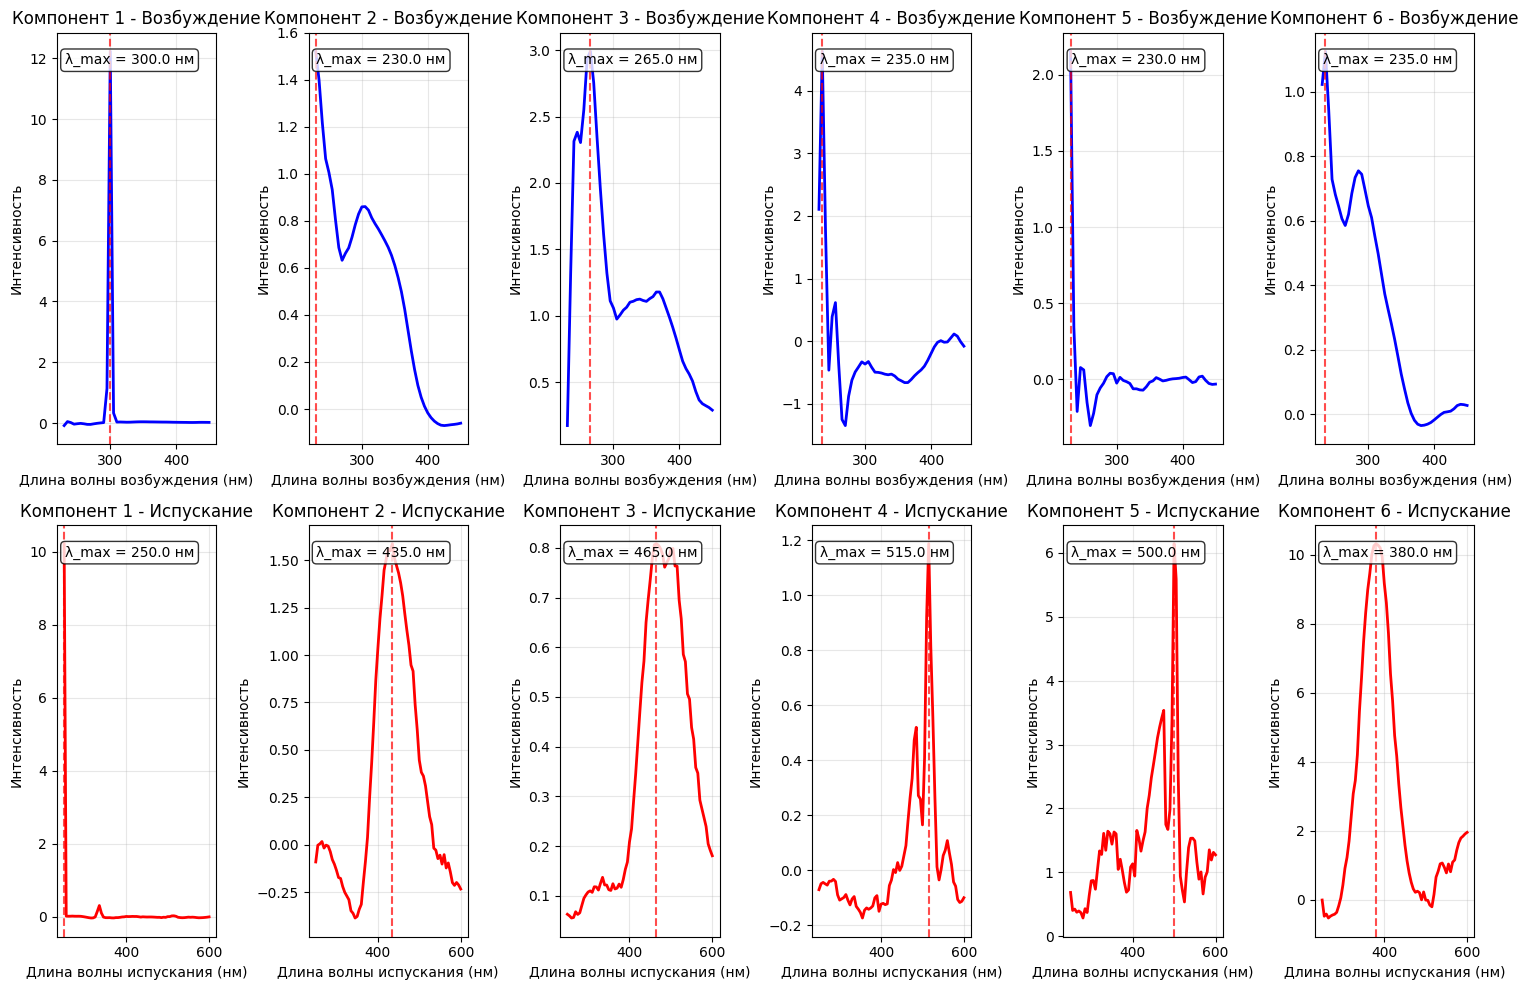

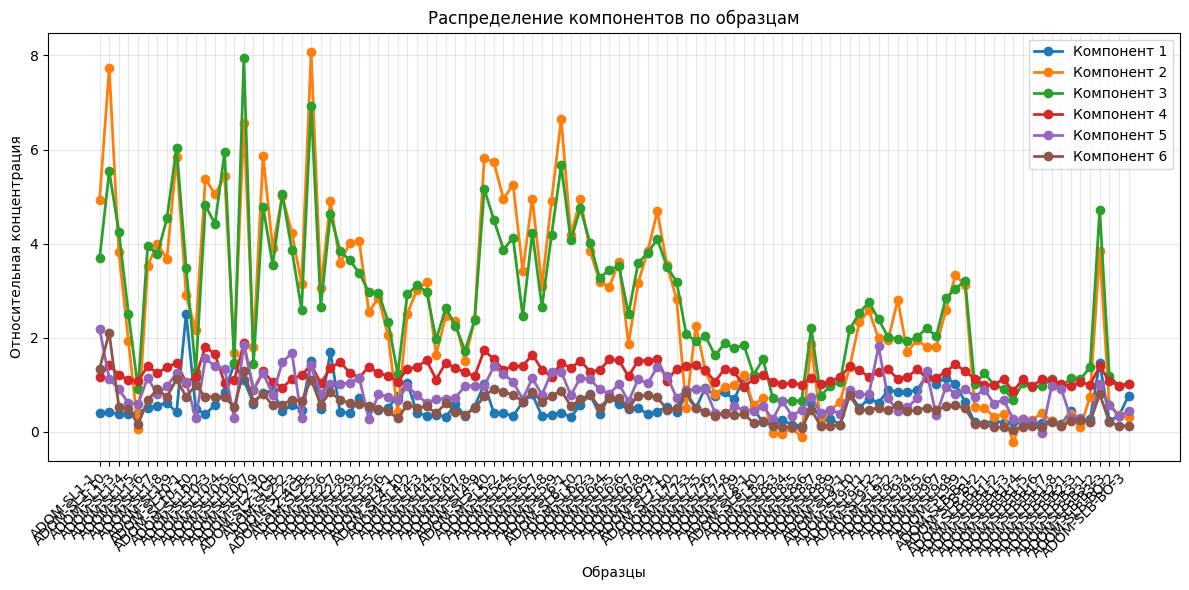

СВОДКА ПО КОМПОНЕНТАМ PARAFAC
Компонент 1:
  Возбуждение: λ_max = 300.0 нм
  Испускание: λ_max = 250.0 нм
  Stokes shift: -50.0 нм

Компонент 2:
  Возбуждение: λ_max = 230.0 нм
  Испускание: λ_max = 435.0 нм
  Stokes shift: 205.0 нм

Компонент 3:
  Возбуждение: λ_max = 265.0 нм
  Испускание: λ_max = 465.0 нм
  Stokes shift: 200.0 нм

Компонент 4:
  Возбуждение: λ_max = 235.0 нм
  Испускание: λ_max = 515.0 нм
  Stokes shift: 280.0 нм

Компонент 5:
  Возбуждение: λ_max = 230.0 нм
  Испускание: λ_max = 500.0 нм
  Stokes shift: 270.0 нм

Компонент 6:
  Возбуждение: λ_max = 235.0 нм
  Испускание: λ_max = 380.0 нм
  Stokes shift: 145.0 нм



In [37]:
# Простой пример
analyzer = OpticalDataAnalyzer(n_components=6)

# Запуск с реальными длинами волн
factors = analyzer.fit_parafac(
    X=eem_tensor,
    excitation_wavelengths=ex_waves,
    emission_wavelengths=em_waves,
    sample_names=sp_names
)

# Визуализация
analyzer.plot_component_profiles()
analyzer.plot_concentration_profiles()
analyzer.print_component_summary()